### Dealing with Outliers

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import statistics as stat
import matplotlib.pyplot as plt
import random

In [2]:
df = sns.load_dataset("titanic")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
numerical_columns = df.select_dtypes(include=['float64', 'int64'])
numerical_columns


,survived,pclass,age,sibsp,parch,fare
0,0,3,22.0,1,0,7.2500
1,1,1,38.0,1,0,71.2833
2,1,3,26.0,0,0,7.9250
3,1,1,35.0,1,0,53.1000
4,0,3,35.0,0,0,8.0500
...,...,...,...,...,...,...
886,0,2,27.0,0,0,13.0000
887,1,1,19.0,0,0,30.0000
888,0,3,NaN,1,2,23.4500
889,1,1,26.0,0,0,30.0000


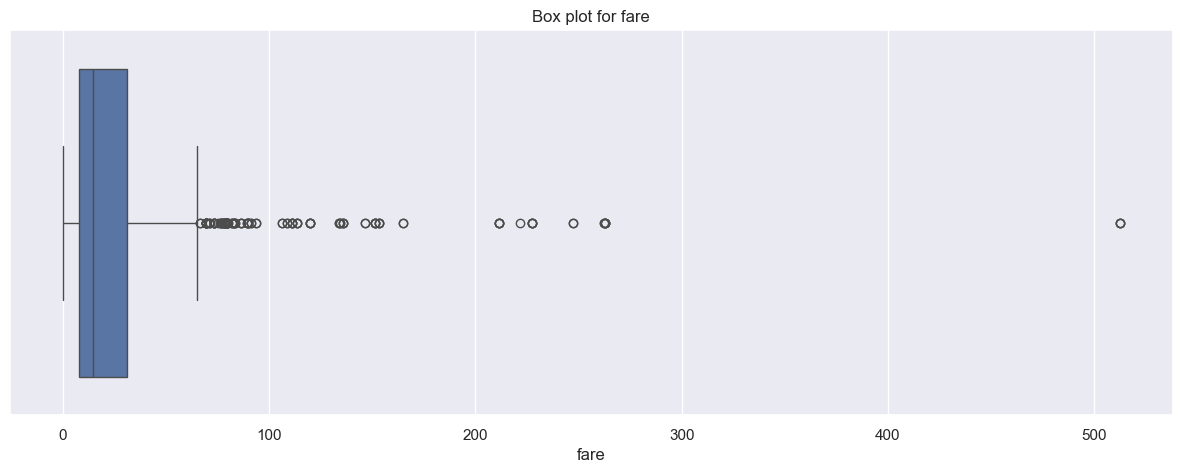

In [5]:
sns.set(rc={'figure.figsize':(15,5)})
sns.boxplot(data=numerical_columns['fare'], orient="h")
plt.title('Box plot for fare')
plt.show()


In [12]:
Q1 = numerical_columns['fare'].quantile(0.25)
Q3 = numerical_columns['fare'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = numerical_columns[(numerical_columns['fare'] < lower_bound) | (numerical_columns['fare'] > upper_bound)]

In [7]:
print(lower_bound, upper_bound)

-26.724 65.6344


In [13]:
outliers

,survived,pclass,age,sibsp,parch,fare
1,1,1,38.0,1,0,71.2833
27,0,1,19.0,3,2,263.0000
31,1,1,NaN,1,0,146.5208
34,0,1,28.0,1,0,82.1708
52,1,1,49.0,1,0,76.7292
...,...,...,...,...,...,...
846,0,3,NaN,8,2,69.5500
849,1,1,NaN,1,0,89.1042
856,1,1,45.0,1,1,164.8667
863,0,3,NaN,8,2,69.5500


Dealing with outliers

1. Remove Outliers

In [10]:
# Calculate Q1 (25th percentile) and Q3 (75th percentile)
Q1 = df['fare'].quantile(0.25)
Q3 = df['fare'].quantile(0.75)

# Calculate the Interquartile Range
IQR = Q3 - Q1

# Calculate the lower and upper bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Remove outliers
df_no_outliers = df[(df['fare'] >= lower_bound) & (df['fare'] <= upper_bound)]

# Verify the result
print(f"Original shape: {df.shape}")
print(f"Shape without outliers: {df_no_outliers.shape}")


Original shape: (891, 15)
Shape without outliers: (775, 15)


2. Transform Data

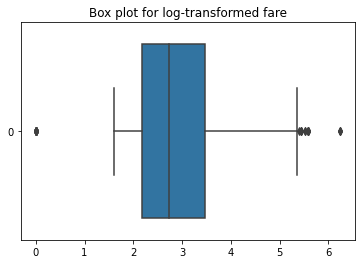

In [13]:
import numpy as np

# Apply log transformation
df['log_fare'] = np.log(df['fare'] + 1)  # Adding 1 to avoid log(0)

# Visualize the transformed data
sns.boxplot(data=df['log_fare'], orient="h")
plt.title('Box plot for log-transformed fare')
plt.show()


3. Cap or Floor Outliers

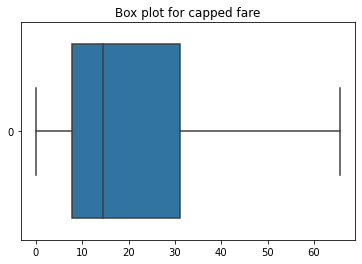

In [14]:
# Cap the fare column
df['fare_capped'] = np.where(df['fare'] > upper_bound, upper_bound, 
                             np.where(df['fare'] < lower_bound, lower_bound, df['fare']))

# Verify the result
sns.boxplot(data=df['fare_capped'], orient="h")
plt.title('Box plot for capped fare')
plt.show()


4. Impute Outliers

In [26]:
# Replace outliers with the median fare
median_fare = df['fare'].median()
df['fare_imputed'] = np.where(df['fare'] > upper_bound, median_fare, 
                              np.where(df['fare'] < lower_bound, median_fare, df['fare']))


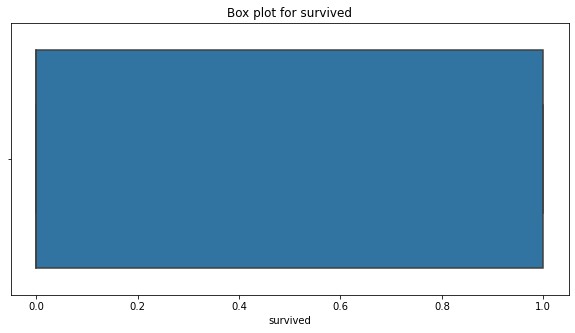

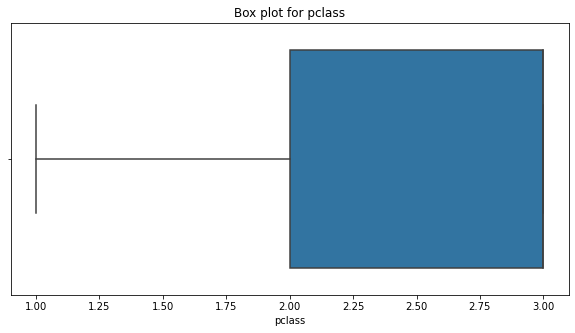

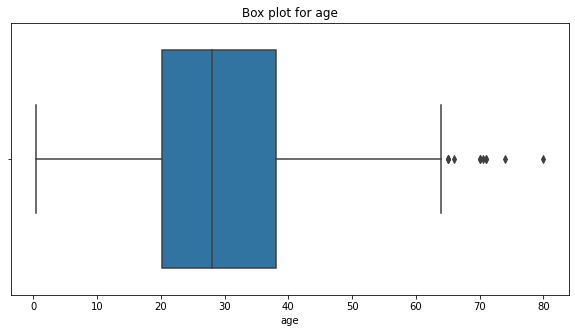

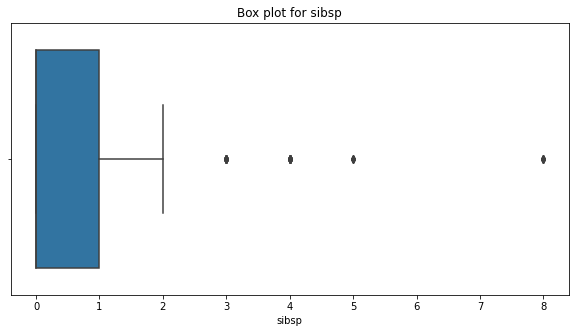

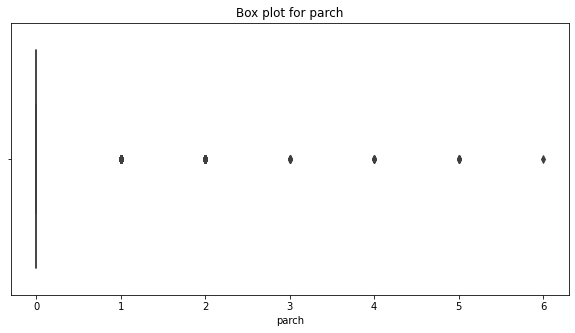

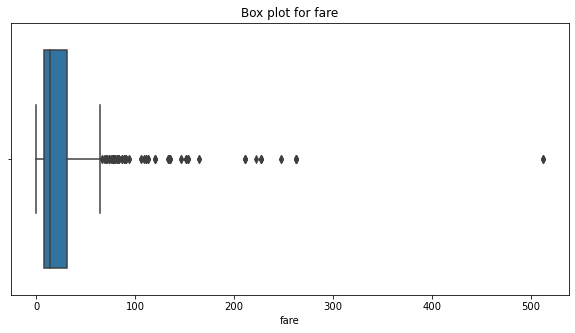

In [8]:
import matplotlib.pyplot as plt

# Plot box plots to visualize outliers
for column in numerical_columns:
    plt.figure(figsize=(10, 5))
    sns.boxplot(x=df[column])
    plt.title(f'Box plot for {column}')
    plt.show()


### Dealing with Skewness

In [16]:
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import boxcox

df = sns.load_dataset("titanic")

# Handle missing values for numerical columns to avoid errors in transformations
df['age'].fillna(df['age'].median(), inplace=True)
df['fare'].fillna(df['fare'].median(), inplace=True)

# Original Skewness
original_skewness = df[['age', 'fare']].skew()
print("Original Skewness:")
print(original_skewness)


Original Skewness:
age     0.510245
fare    4.787317
dtype: float64


C:\Users\richa\AppData\Local\Temp\ipykernel_19908\4215522959.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['age'].fillna(df['age'].median(), inplace=True)
C:\Users\richa\AppData\Local\Temp\ipykernel_19908\4215522959.py:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For

In [10]:
from scipy.stats import boxcox
# Log Transformation
df['log_fare'] = np.log(df['fare'] + 1)  # Adding 1 to avoid log(0)

# Square Root Transformation
df['sqrt_fare'] = np.sqrt(df['fare'])

# Cube Root Transformation
df['cbrt_fare'] = np.cbrt(df['fare'])

# Box-Cox Transformation
df['boxcox_fare'],lmbda = boxcox(df['fare'] + 1)  # Adding 1 to avoid log(0)

In [ ]:
# Calculate skewness after transformations
transformed_skewness = df[['log_fare', 'sqrt_fare', 'cbrt_fare', 'boxcox_fare']].skew()
print("Transformed Skewness:")
print(transformed_skewness)

# Visualize the transformed distributions
plt.figure(figsize=(18, 12))

# Original Distribution
plt.subplot(3, 2, 1)
sns.histplot(df['fare'], kde=True)
plt.title('Original Fare')

# Log Transformation
plt.subplot(3, 2, 2)
sns.histplot(df['log_fare'], kde=True)
plt.title('Log Transformed Fare')

# Square Root Transformation
plt.subplot(3, 2, 3)
sns.histplot(df['sqrt_fare'], kde=True)
plt.title('Square Root Transformed Fare')

# Cube Root Transformation
plt.subplot(3, 2, 4)
sns.histplot(df['cbrt_fare'], kde=True)
plt.title('Cube Root Transformed Fare')

# Box-Cox Transformation
plt.subplot(3, 2, 5)
sns.histplot(df['boxcox_fare'], kde=True)
plt.title('Box-Cox Transformed Fare')

plt.tight_layout()
plt.show()